# Veri Zemini — EDA & Sanity Check

Dört veri dosyasını yükler, yapısal doğrulama yapar ve temel dağılımları gösterir.  
**Bölüm 6.1 — Adım 14 & 15**

In [11]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_all, sanity_check
from src.layer2_assignment.distance import build_distance_matrix, validate_distance_matrix

## 1. Veri Yükleme & Sanity Check

In [12]:
data = load_all()
sanity_check(data)

df_talep    = data['desi_talep']
df_koord    = data['koordinatlar']
df_maliyet  = data['arac_maliyet']
df_kiralik  = data['kiralik_araclar']

print(f"Desi talep : {df_talep.shape}")
print(f"Koordinatlar: {df_koord.shape}")
print(f"Araç maliyet: {df_maliyet.shape}")
print(f"Kiralık araç: {df_kiralik.shape}")

[sanity_check] OK — 89 hat | 130 gün | 18 TM | 10770 satır | negatif desi yok
Desi talep : (10770, 4)
Koordinatlar: (18, 3)
Araç maliyet: (4, 6)
Kiralık araç: (12, 4)


## 2. Hat Bazlı Talep Dağılımı

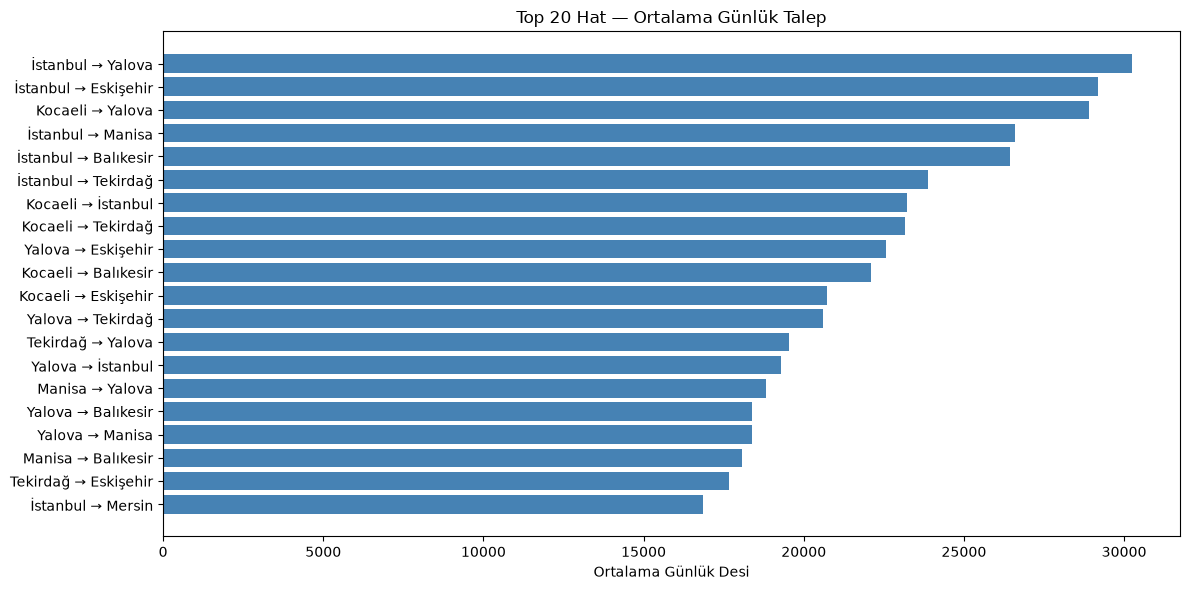

In [13]:
hat_talep = (
    df_talep
    .groupby(['cikis_tm', 'varis_tm'])['desi']
    .mean()
    .reset_index()
    .rename(columns={'desi': 'ortalama_desi'})
    .sort_values('ortalama_desi', ascending=False)
    .head(20)
)

hat_talep['hat'] = hat_talep['cikis_tm'] + ' → ' + hat_talep['varis_tm']

fig, ax = plt.subplots(figsize=(12, 6))
ax.barh(hat_talep['hat'], hat_talep['ortalama_desi'], color='steelblue')
ax.set_xlabel('Ortalama Günlük Desi')
ax.set_title('Top 20 Hat — Ortalama Günlük Talep')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Günlük Talep Trendi

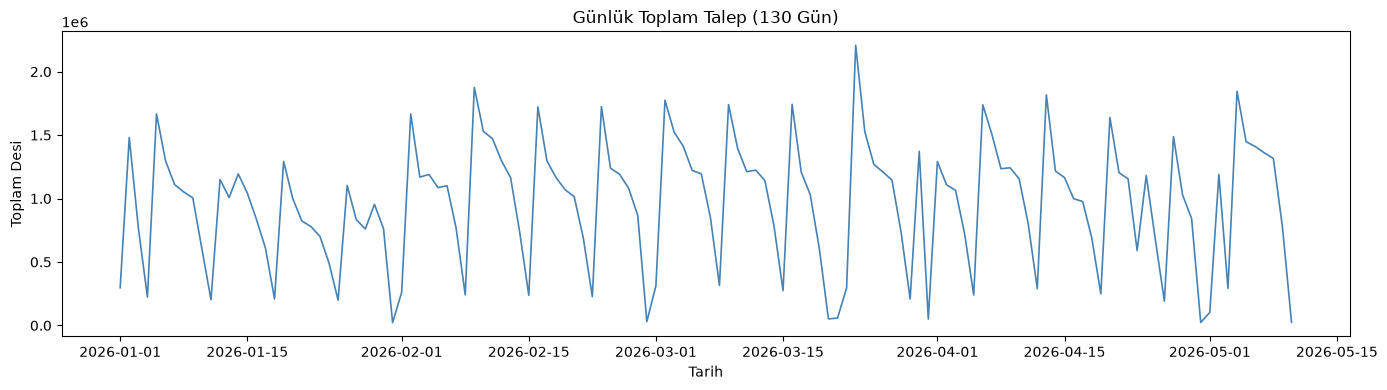

In [14]:
gunluk = df_talep.groupby('tarih')['desi'].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(gunluk['tarih'], gunluk['desi'], linewidth=1.2, color='steelblue')
ax.set_xlabel('Tarih')
ax.set_ylabel('Toplam Desi')
ax.set_title('Günlük Toplam Talep (130 Gün)')
plt.tight_layout()
plt.show()

## 4. 18×18 Mesafe Matrisi Isı Haritası

[validate_distance_matrix] OK — 18×18 | simetrik | köşegen=0 | tüm değerler ≥ 0


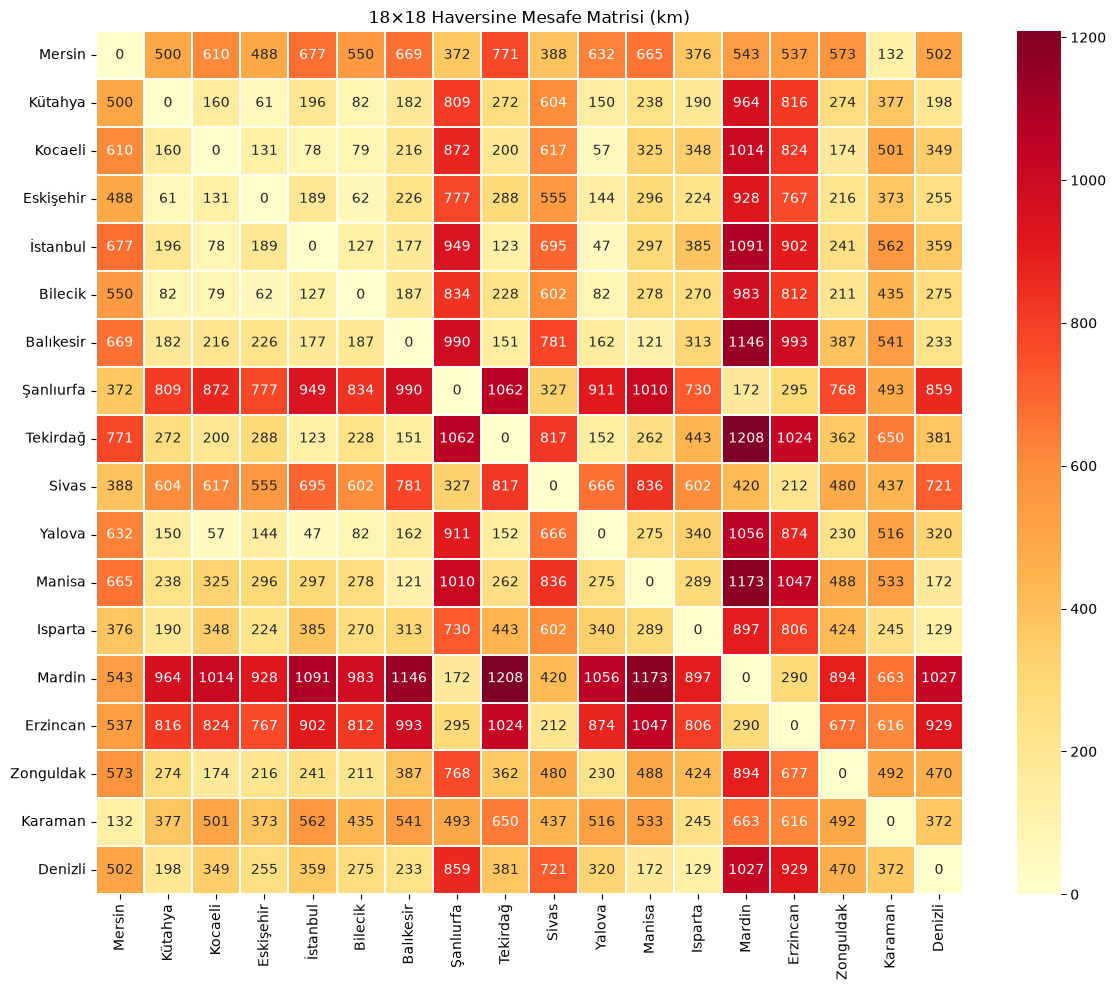

In [15]:
dist_df = build_distance_matrix(df_koord)
validate_distance_matrix(dist_df)

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    dist_df,
    annot=True, fmt='.0f',
    cmap='YlOrRd',
    linewidths=0.3,
    ax=ax
)
ax.set_title('18×18 Haversine Mesafe Matrisi (km)')
plt.tight_layout()
plt.show()